# 03 · Fairness audit and mitigation

This notebook walks through the main results: how the deployed model treats each group on the held-out test set, what each mitigation method buys, and what the pre-flight check says. At the end it shows how to use the `fairpath` library on your own predictions.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORTS = ROOT / "reports"
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e1e0d9", "font.size": 10})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
name = "dropout"
final = json.loads((REPORTS / name / "final_model.json").read_text())
study = json.loads((REPORTS / name / "fairness_study.json").read_text())
pre = json.loads((REPORTS / name / "preflight.json").read_text())
print(final["model_label"], "| deployed threshold", final["deployed"]["threshold"], "| test n", final["n_test"])
pd.DataFrame({k: {"deployed": v["value"], "lo": v["lo"], "hi": v["hi"]} for k, v in final["test_metrics"]["deployed"].items() if "lo" in v}).T

XGBoost | deployed threshold 0.37 | test n 726


,deployed,lo,hi
roc_auc,0.861,0.833,0.888
pr_auc,0.828,0.792,0.862
brier,0.142,0.128,0.156
ece,0.030,0.028,0.062
f1,0.725,0.689,0.759
precision,0.688,0.650,0.728
recall,0.768,0.718,0.817
balanced_accuracy,0.772,0.741,0.802


## Group-level behaviour on the test set

Each row is a group; the deployed model is blind to gender and trained with Reweighing.

In [2]:
g = pd.DataFrame(final["fairness"]["gender"]["deployed"]["groups"])
g[["label", "n", "base_rate", "flag_rate", "tpr", "fpr", "ppv", "ece", "coverage"]]

,label,n,base_rate,flag_rate,tpr,fpr,ppv,ece,coverage
0,Female,476,0.303,0.357,0.750,0.187,0.635,0.060,0.920
1,Male,250,0.560,0.588,0.786,0.336,0.748,0.064,0.896


In [3]:
gaps = final["fairness"]["gender"]
pd.DataFrame({k: {"deployed": gaps["deployed"]["gaps"][k]["value"], "95% CI": f"[{gaps['deployed']['gaps'][k]['lo']:.3f}, {gaps['deployed']['gaps'][k]['hi']:.3f}]",
                  "perm p": gaps["deployed"]["gaps"][k].get("perm_p"), "unmitigated": gaps["baseline"]["gaps"][k]["value"]}
              for k in ["spd", "tpr_gap", "fpr_gap", "eodds", "ppv_gap"]}).T

,deployed,95% CI,perm p,unmitigated
spd,0.231,"[0.163, 0.298]",0.001,0.389
tpr_gap,0.036,"[0.001, 0.127]",0.499,0.184
fpr_gap,0.15,"[0.056, 0.243]",0.001,0.328
eodds,0.15,"[0.062, 0.243]",0.006,0.328
ppv_gap,0.113,"[0.037, 0.186]",None,0.018


## Mitigation methods side by side (5x2 CV on the development split)

In [4]:
best = [m for m in study["models"] if m != "logistic_regression"][-1] if len(study["models"]) > 1 else study["models"][0]
blk = study["summary"]["gender"][best]
m = pd.DataFrame([{"method": e["label"], "stage": e["stage"], "F1": e["f1"]["mean"], "AUC": e["roc_auc"]["mean"],
                   "SPD": e["spd"]["mean"], "EOdds": e["eodds"]["mean"], "p EOdds (Holm)": e.get("tests", {}).get("eodds", {}).get("p_holm"),
                   "group used at prediction": e["needs_sensitive_at_prediction"], "Pareto": e["pareto"]} for e in blk["methods"]])
m

,method,stage,F1,AUC,SPD,EOdds,p EOdds (Holm),group used at prediction,Pareto
0,No mitigation (aware),none,0.734,0.860,0.384,0.298,NaN,True,True
1,Fairness through unawareness,pre,0.728,0.856,0.266,0.173,0.016,False,True
2,Reweighing (aware),pre,0.714,0.850,0.199,0.112,0.016,True,True
3,Blind + Reweighing (deployed),pre,0.720,0.852,0.228,0.135,0.016,False,True
4,Exponentiated Gradient (DP),in,0.649,0.747,0.054,0.177,0.016,True,False
5,Exponentiated Gradient (EO),in,0.696,0.769,0.187,0.105,0.016,True,True
6,Group thresholds (thesis),post,0.558,0.860,0.096,0.073,0.016,True,True
7,ThresholdOptimizer (EO),post,0.677,0.756,0.143,0.085,0.016,True,True
8,ThresholdOptimizer (DP),post,0.676,0.761,0.049,0.153,0.016,True,False


Text(0.0, 1.0, 'Fairness vs accuracy')

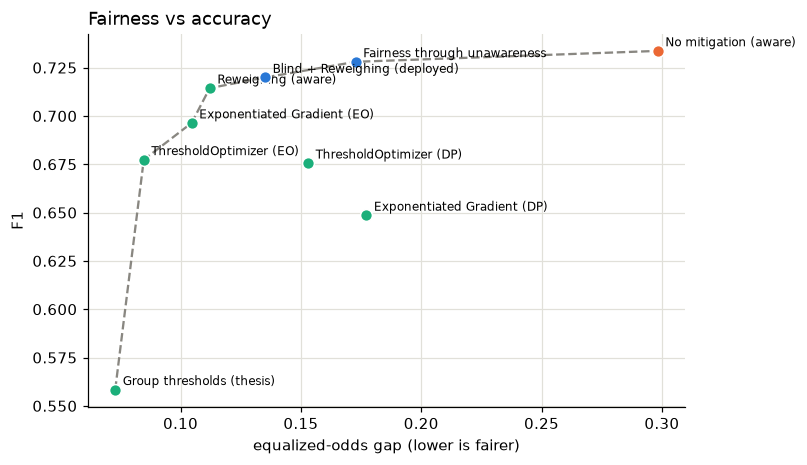

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.4))
for _, r in m.iterrows():
    c = ORANGE if r.method.startswith("No mitigation") else (AQUA if r["group used at prediction"] else BLUE)
    ax.scatter(r.EOdds, r.F1, color=c, s=60, edgecolor="white", zorder=3)
    ax.annotate(r.method, (r.EOdds, r.F1), xytext=(5, 3), textcoords="offset points", fontsize=8)
front = m[m.Pareto].sort_values("EOdds")
ax.plot(front.EOdds, front.F1, ls="--", color="#898781")
ax.set_xlabel("equalized-odds gap (lower is fairer)"); ax.set_ylabel("F1"); ax.set_title("Fairness vs accuracy", loc="left")

## Pre-flight check

v1 is the thesis rule, v2 the revised version. Compare the two datasets:

In [6]:
rows = []
for ds in ["dropout", "student_mat"]:
    p = json.loads((REPORTS / ds / "preflight.json").read_text())
    for axis, v in p["axes"].items():
        rows.append({"dataset": ds, "axis": v["label"], "v1": v["v1"]["verdict"], "v2": v["v2"]["verdict"],
                     **{f"v2 check {c['id']}": c["value"] for c in v["v2"]["checks"]}})
pd.DataFrame(rows)

,dataset,axis,v1,v2,v2 check 1,v2 check 2,v2 check 3
0,dropout,Gender,Attempt mitigation,Mitigate and measure,0.037,5.000e-04,0.362
1,dropout,Debtor status,Do not mitigate,"Clear gap: mitigate, but only changes larger t...",0.056,5.000e-04,0.454
2,dropout,Age at enrolment,Do not mitigate,"Clear gap: mitigate, but only changes larger t...",0.055,5.000e-04,0.529
3,dropout,Gender x Debtor status,Do not mitigate,"Clear gap: mitigate, but only changes larger t...",0.107,5.000e-04,0.723
4,dropout,Gender x Age at enrolment,Do not mitigate,"Clear gap: mitigate, but only changes larger t...",0.086,5.000e-04,0.731
5,student_mat,Sex,Do not mitigate,"Insufficient data: report intervals, do not cl...",0.104,8.046e-01,0.002
6,student_mat,Home address,Do not mitigate,"Insufficient data: report intervals, do not cl...",0.129,1.019e-01,0.007
7,student_mat,Parental education,Do not mitigate,"Clear gap: mitigate, but only changes larger t...",0.109,5.000e-04,0.257
8,student_mat,Sex x Home address,Do not mitigate,"Insufficient data: report intervals, do not cl...",0.230,4.638e-01,0.053


## Using the library on your own predictions

Everything above is built from a few small functions. Here they are on made-up scores, so this cell runs anywhere:

In [7]:
from fairpath.fairness.metrics import fairness_report
from fairpath.fairness.preflight import preflight_v2
rng = np.random.default_rng(1)
n = 1500
group = rng.choice(["A", "B"], n, p=[0.6, 0.4])
y = (rng.random(n) < np.where(group == "A", 0.3, 0.45)).astype(int)
score = np.clip(0.45 * y + rng.normal(0.3, 0.15, n) + 0.05 * (group == "B"), 0, 1)
rep = fairness_report(y, score, group, threshold=0.5, n_boot=500, n_perm=500)
print({k: round(v["value"], 3) for k, v in rep["gaps"].items()})
print(preflight_v2(y, score, group, n_boot=500, n_perm=500)["verdict"])

{'spd': 0.172, 'di_ratio': 0.684, 'tpr_gap': 0.019, 'fpr_gap': 0.104, 'fnr_gap': 0.019, 'eodds': 0.104, 'ppv_gap': 0.035, 'calibration_gap': 0.011, 'accuracy_gap': 0.043}


Clear gap: mitigate, but only changes larger than about 0.07 can be confirmed on data this size
